In [2]:
# --- 1. Importações ---
import pandas as pd
from pandas import DataFrame
import os
import matplotlib.pyplot as plt
import matplotlib.patches as patches  # <<< ADIÇÃO IMPORTANTE PARA A FUNÇÃO DE PLOTAGEM
from tqdm.notebook import tqdm

In [57]:
dfr = pd.read_parquet('spadl.parquet')
dfr.head(20)

,game_id,period_id,team_id,player_id,start_x,start_y,end_x,end_y,original_event_id,time_seconds,type_id,type_name,result_id,result_name,bodypart_id,bodypart_name,action_id
0,13335,1,5,15620,0.503105,0.504544,0.326924,0.436265,12926009.0,153.887,0,pass,1,success,5,foot_right,0
1,13335,1,5,4696,0.329743,0.457456,0.760200,0.735603,12926647.0,156.623,0,pass,0,fail,5,foot_right,1
2,13335,1,5,14278,0.760200,0.735603,NaN,NaN,12926642.0,159.860,9,tackle,0,fail,0,foot,2
3,13335,1,11,284,0.760200,0.735603,NaN,NaN,12926642.0,159.860,9,tackle,1,success,0,foot,3
4,13335,1,5,13068,0.760200,0.735603,NaN,NaN,12926642.0,159.860,9,tackle,0,fail,0,foot,4
5,13335,1,11,284,0.760200,0.735603,0.581067,0.886603,20246849.0,159.893,18,clearance,1,success,0,foot,5
6,13335,1,5,6018,0.581067,0.886603,0.392533,0.837544,12926648.0,162.763,0,pass,1,success,4,foot_left,6
7,13335,1,5,2031,0.387505,0.806926,0.267390,0.451279,12926652.0,167.467,0,pass,1,success,5,foot_right,7
8,13335,1,5,4696,0.265010,0.443485,0.228162,0.667029,12926662.0,170.704,0,pass,1,success,4,foot_left,8
9,13335,1,5,2031,0.233981,0.591779,0.525038,0.831176,12926665.0,175.008,0,pass,0,fail,5,foot_right,9


In [4]:
# %% [markdown]
# # Pipeline Completo: Padronização e Verificação de Dados SPADL
# 
# **Objetivo:** Executar um pipeline completo que:
# 1. Carrega os dados SPADL originais e o mapa de times.
# 2. Aplica a função de padronização `play_left_to_right` que utiliza a coluna `homeTeamStartLeft` para uma lógica precisa.
# 3. Utiliza uma função de visualização avançada para criar um gráfico comparativo "Antes vs. Depois", confirmando o sucesso da padronização.
# 4. Salva o resultado final como `spadl_ltr.parquet`.




# ---
# ## 2. Definição das Funções Principais
# *Aqui definimos as duas ferramentas que você criou: a de transformação e a de visualização.*

# %%
def play_left_to_right_with_map(actions_df: pd.DataFrame, team_map_df: pd.DataFrame) -> pd.DataFrame:
    """
    Ajusta as coordenadas das ações para que todas fluam da esquerda para a direita,
    usando a informação de 'homeTeamStartLeft' para uma lógica precisa.
    """
    print("Iniciando a padronização 'play_left_to_right'...")
    # 1. Clonar e garantir tipos
    actions_df = actions_df.copy()
    actions_df['game_id'] = actions_df['game_id'].astype(int)
    team_map_df['game_id'] = team_map_df['game_id'].astype(int)

    # Verifica se os game_ids batem para fazer o merge
    if not set(actions_df['game_id']).issubset(set(team_map_df['game_id'])):
        # conta quantos game_ids estão faltando
        missing_game_ids = set(actions_df['game_id']) - set(team_map_df['game_id'])
        print(f"⚠️ {len(missing_game_ids)} game_ids estão faltando no team_map_df: {missing_game_ids}")
        raise ValueError("Alguns game_id em actions_df não estão presentes em team_map_df.")
    
    # 2. Corrigir coordenadas fora do intervalo [0, 1]
    coord_cols = ['start_x', 'end_x', 'start_y', 'end_y']
    for col in coord_cols:
        if actions_df[col].hasnans or (actions_df[col] < 0).any() or (actions_df[col] > 1).any():
            print(f'⚠️ Corrigindo coordenadas fora de [0,1] na coluna: {col}')
            actions_df[col] = actions_df[col].clip(lower=0, upper=1)

    # 3. Merge com mapeamento de times
    df_merged = pd.merge(actions_df, team_map_df, on='game_id', how='left')
    df_ltr = df_merged.copy()
    df_ltr['team_id'] = df_ltr['team_id'].astype(float)
    df_ltr['home_team_id'] = df_ltr['home_team_id'].astype(float)
    df_ltr['away_team_id'] = df_ltr['away_team_id'].astype(float)

    # 5. Definir condições de inversão
    flip_home_p1 = (df_ltr['period_id'] == 1) & (df_ltr['team_id'] == df_ltr['home_team_id']) & (df_ltr['homeTeamStartLeft'] == 0)
    flip_away_p1 = (df_ltr['period_id'] == 1) & (df_ltr['team_id'] == df_ltr['away_team_id']) & (df_ltr['homeTeamStartLeft'] == 1)
    flip_home_p2 = (df_ltr['period_id'] != 1) & (df_ltr['team_id'] == df_ltr['home_team_id']) & (df_ltr['homeTeamStartLeft'] == 1)
    flip_away_p2 = (df_ltr['period_id'] != 1) & (df_ltr['team_id'] == df_ltr['away_team_id']) & (df_ltr['homeTeamStartLeft'] == 0)

    actions_to_flip = flip_home_p1 | flip_away_p1 | flip_home_p2 | flip_away_p2

    # 6. Aplicar inversão de coordenadas
    df_ltr.loc[actions_to_flip, coord_cols] = 1 - df_ltr.loc[actions_to_flip, coord_cols]

    # 7. Remover colunas auxiliares
    cols_to_drop = ['home_team_id', 'away_team_id', 'homeTeamStartLeft']
    df_ltr = df_ltr.drop(columns=cols_to_drop, errors='ignore')

    print("Padronização concluída.")
    return df_ltr


In [84]:

def plot_action_directions(actions_df: pd.DataFrame, game_id_to_plot: int, title: str):
    """
    Plota um campo de futebol e desenha as direções das ações para um jogo específico.
    """
    actions_df['game_id'] = actions_df['game_id'].astype(int)
    df_to_plot = actions_df[actions_df['game_id'] == game_id_to_plot].copy()
    if df_to_plot.empty:
        print(f"Aviso: Nenhum dado encontrado para o game_id {game_id_to_plot}.")
        return

    # Pega uma amostra para não poluir o gráfico
    if len(df_to_plot) > 300:
        df_to_plot = df_to_plot.sample(300, random_state=42)

    fig, ax = plt.subplots(figsize=(16, 10))
    ax.set_title(f"{title}\n(Jogo ID: {game_id_to_plot})", fontsize=16)
    
    # Desenha o campo
    ax.add_patch(patches.Rectangle((0, 0), 1, 1, facecolor='#61a751', alpha=0.6, zorder=0))
    ax.plot([0, 1, 1, 0, 0], [0, 0, 1, 1, 0], color='white', linewidth=2)
    ax.plot([0.5, 0.5], [0, 1], color='white', linewidth=2)
    ax.add_artist(plt.Circle((0.5, 0.5), 0.08, color='white', fill=False, linewidth=2))
    ax.add_patch(patches.Rectangle((0, 0.19), 0.16, 0.62, fill=False, edgecolor='white', linewidth=2))
    ax.add_patch(patches.Rectangle((1 - 0.16, 0.19), 0.16, 0.62, fill=False, edgecolor='white', linewidth=2))
    ax.set_xticks([]); ax.set_yticks([])

    # Desenha as setas
    for action in df_to_plot.itertuples():
        if pd.notna(action.start_x) and pd.notna(action.end_x):
            dx = action.end_x - action.start_x
            color = 'green' if dx >= 0 else 'red'
            ax.arrow(x=action.start_x, y=action.start_y, dx=dx, dy=action.end_y - action.start_y,
                     head_width=0.015, head_length=0.02, color=color, alpha=0.8, length_includes_head=True)
    
    fig.tight_layout()
    plt.show()


In [47]:
import os

# Caminho para a pasta onde os arquivos estão armazenados
caminho_pasta = '../tracking/parquets_standardizados'

# Lista para armazenar os números extraídos dos nomes dos arquivos
numeros_extraidos = []

# Percorre todos os arquivos na pasta
for nome_arquivo in os.listdir(caminho_pasta):
    if nome_arquivo.endswith('_standard.parquet'):
        # Extrai os primeiros 5 caracteres do nome do arquivo
        numero = nome_arquivo[:5]
        numeros_extraidos.append(numero)

# Exibe a lista com todos os números extraídos
print(numeros_extraidos)


['13593', '13612', '13447', '13500', '13490', '13348', '13483', '13457', '13505', '13413', '13603', '13466', '13479', '13605', '13487', '13465', '13514', '13463', '13581', '13522', '13462', '13509', '13510', '13382', '13543', '13345', '13446', '13571', '13527', '13586', '13504', '13427', '13538', '13580', '13544', '13365', '13435', '13391', '13467', '13475', '13360', '13502', '13343', '13472', '13568', '13478', '13596', '13493', '13600', '13346', '13575', '13556', '13610', '13541', '13469', '13604', '13602', '13474', '13455', '13492', '13454', '13523', '13452', '13432', '13347', '13484', '13550', '13507', '13592', '13557', '13499', '13489', '13456', '13486', '13355', '13606', '13548', '13524', '13436', '13565', '13525', '13338', '13554', '13621', '13611', '13445', '13517', '13450', '13336', '13350', '13477', '13613', '13501', '13468', '13620', '13519', '13440', '13529', '13356', '13608', '13555', '13438', '13578', '13585', '13357', '13521', '13353', '13491', '13513', '13451', '13579', 

In [77]:

spadl_original_path = 'spadl.parquet'
team_map_input_path = '../team_map.parquet'
output_path = 'spadl_ltr2.parquet'

try:
    spadl_original = pd.read_parquet(spadl_original_path)
    team_map = pd.read_parquet(team_map_input_path)
except FileNotFoundError as e:
    raise FileNotFoundError(f"Erro ao carregar arquivos necessários: {e}")

In [80]:
spadl_original = spadl_original[spadl_original.game_id.isin(numeros_extraidos)]

In [81]:
team_map['game_id'] = team_map['game_id'].astype(str)
team_map = team_map[team_map.game_id.isin(numeros_extraidos)]
team_map['game_id'] = team_map['game_id'].astype(int)


Iniciando a padronização 'play_left_to_right'...
⚠️ Corrigindo coordenadas fora de [0,1] na coluna: start_x
⚠️ Corrigindo coordenadas fora de [0,1] na coluna: end_x
⚠️ Corrigindo coordenadas fora de [0,1] na coluna: start_y
⚠️ Corrigindo coordenadas fora de [0,1] na coluna: end_y
Padronização concluída.

Arquivo padronizado salvo com sucesso em: 'spadl_ltr2.parquet'


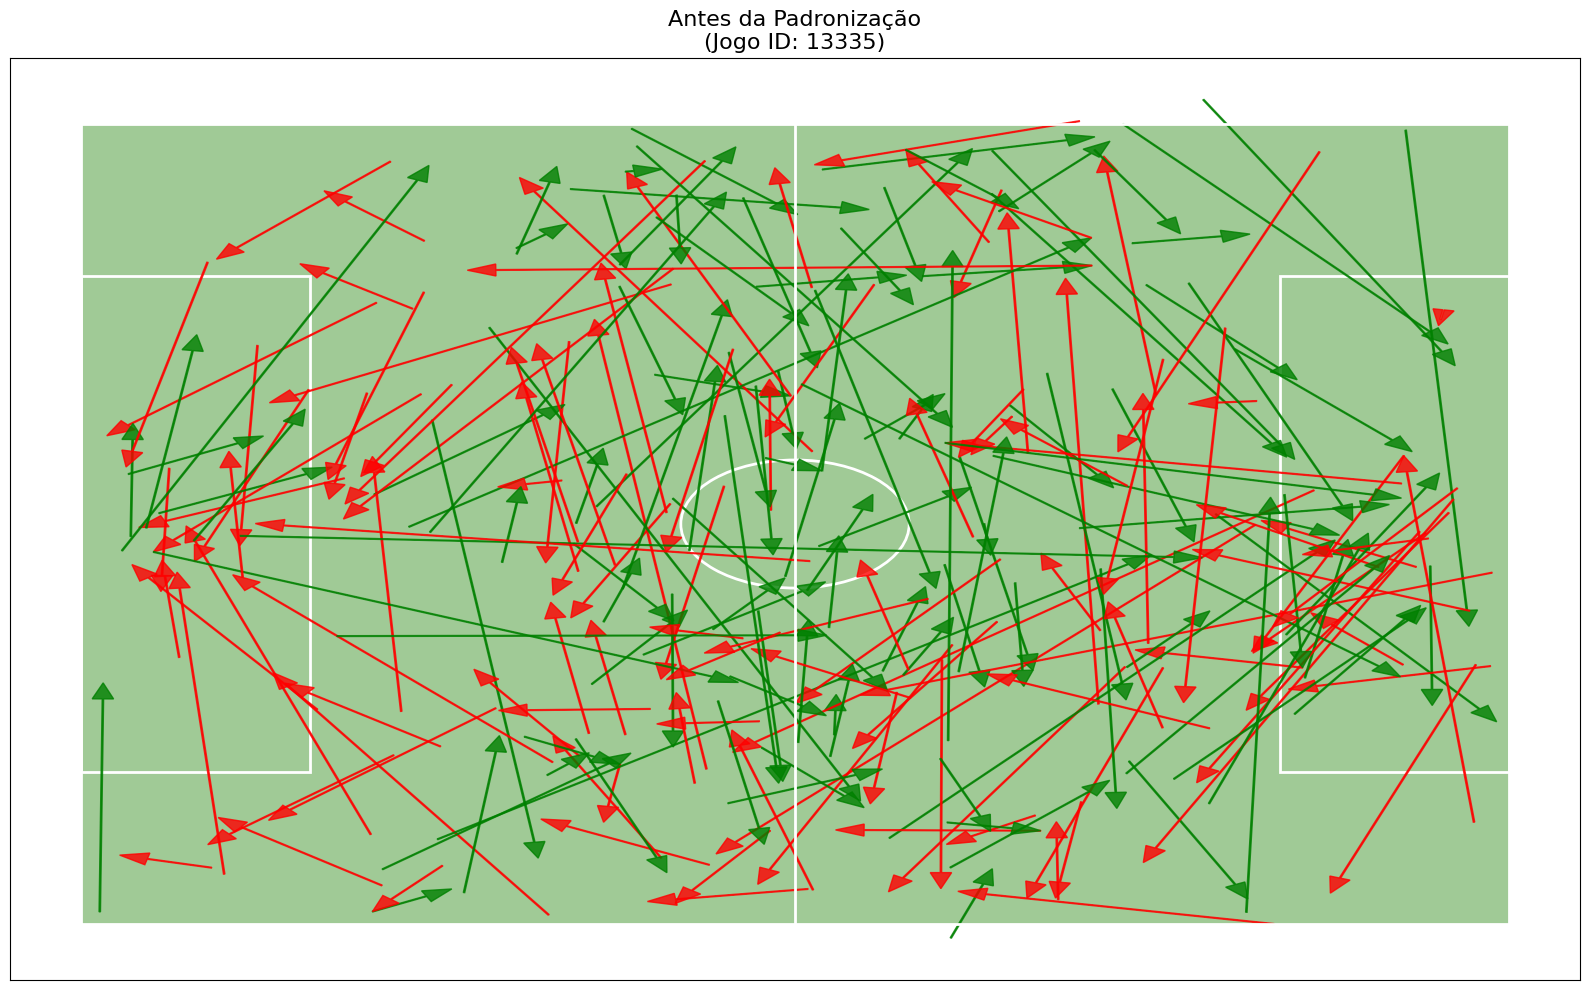

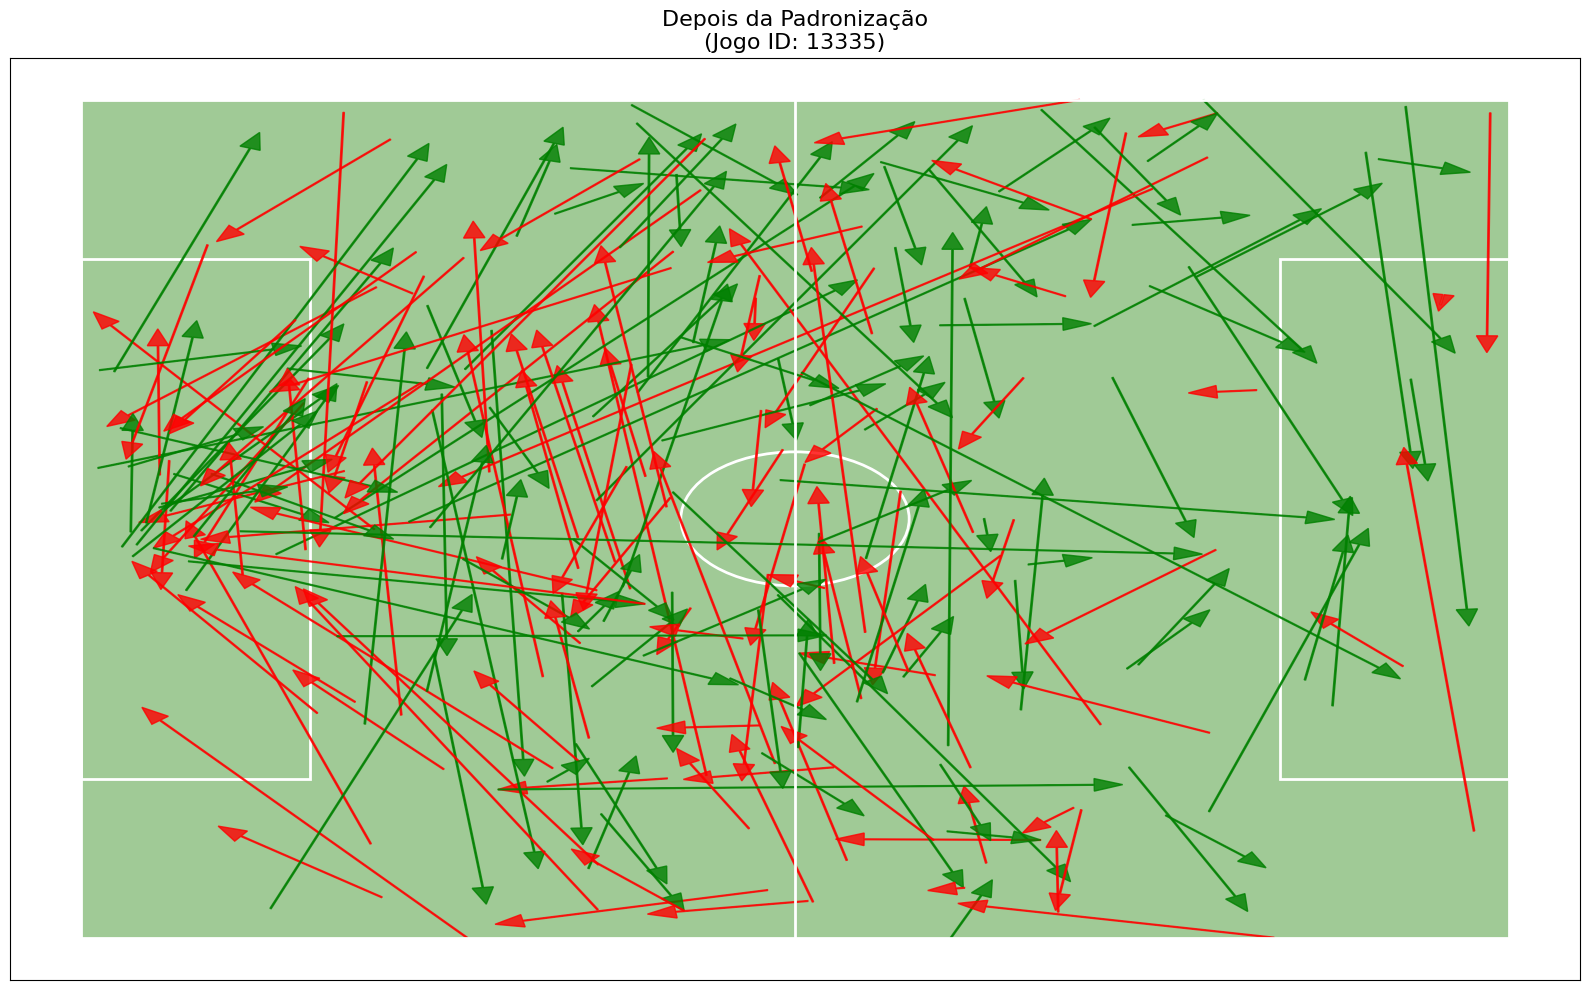

In [ ]:
# --- Executar a Padronização ---
spadl_ltr = play_left_to_right_with_map(spadl_original, team_map)

# --- Salvar o Resultado ---
spadl_ltr.to_parquet(output_path, index=False)
print(f"\nArquivo padronizado salvo com sucesso em: '{output_path}'")

# ## 4. Verificação Visual
# *Agora plotamos os dados antes e depois da transformação para o mesmo jogo para confirmar o resultado.*

# %%
# Escolhe um jogo para visualizar
game_id_para_verificar = team_map['game_id'].iloc[0]

# Plota o gráfico "Antes"
plot_action_directions(
    spadl_original, 
    game_id_to_plot=game_id_para_verificar,
    title="Antes da Padronização"
)

# Plota o gráfico "Depois"
plot_action_directions(
    spadl_ltr, 
    game_id_to_plot=game_id_para_verificar,
    title="Depois da Padronização"
)